# Lab 9 – Morphological Operations

the solution of the tasks and the extra experiments are in the bottom

Ali Jafar Altaweel

2240006456

7MA2

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# imgFile = 'Erosion.jpg'
imgFile = './images/Erosion.jpg'

## 1. Erosion

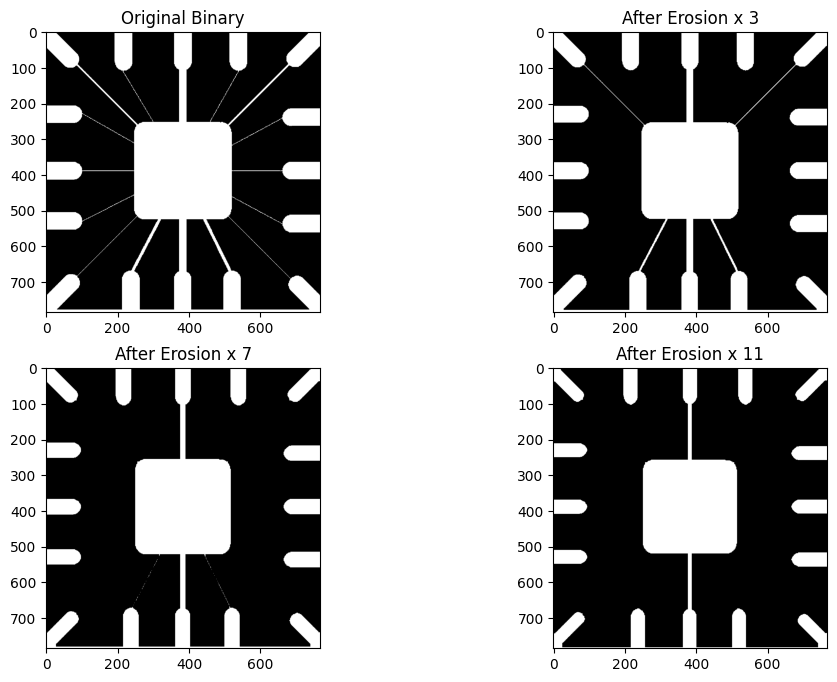

In [2]:
# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)
eroded_img11 = cv2.erode(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Erosion x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Erosion x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Erosion x 11')


plt.show()

## 2. Dilation

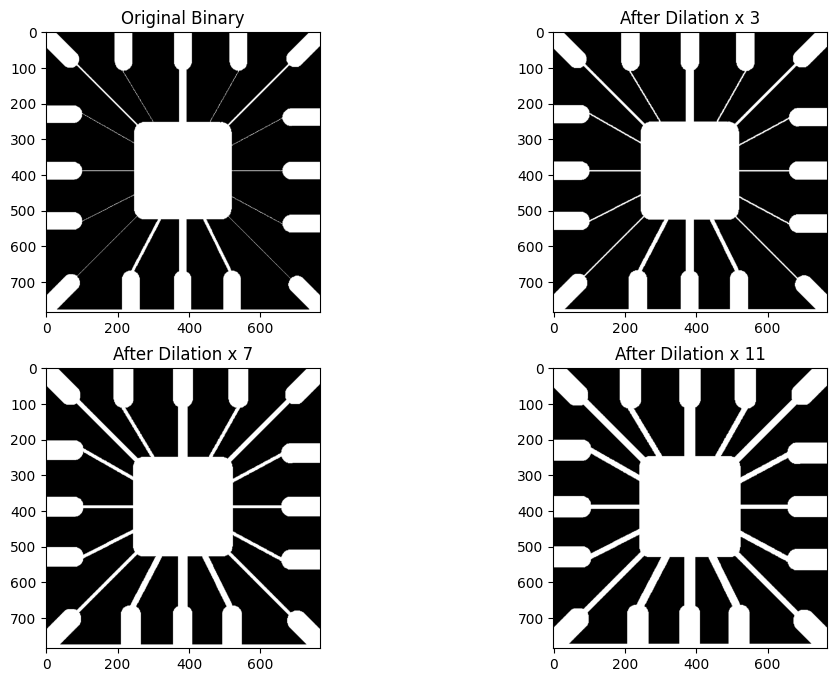

In [3]:
# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.dilate(binary, kernel3, iterations=1)
eroded_img7 = cv2.dilate(binary, kernel7, iterations=1)
eroded_img11 = cv2.dilate(binary, kernel11, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Dilation x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Dilation x 7')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Dilation x 11')


plt.show()

## 3. Opening

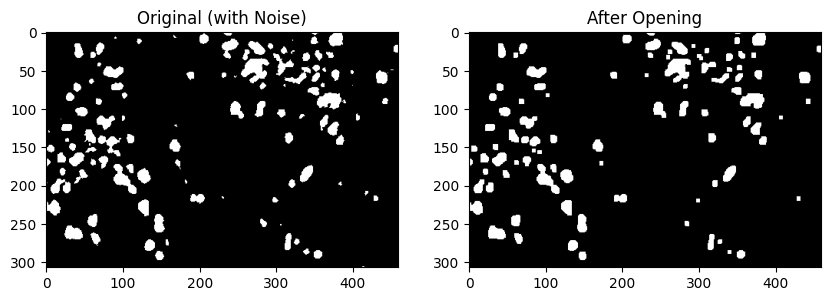

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# imgFile = 'Open_Closing.jpg'
imgFile = './images/Open_Closing.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 5x5 square is a good starting point)
kernel = np.ones((5, 5), np.uint8)

# 3. Apply Opening
# This is equivalent to: dilate(erode(binary))
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(opening, 'gray'), plt.title('After Opening')
plt.show()

## 4. Closing

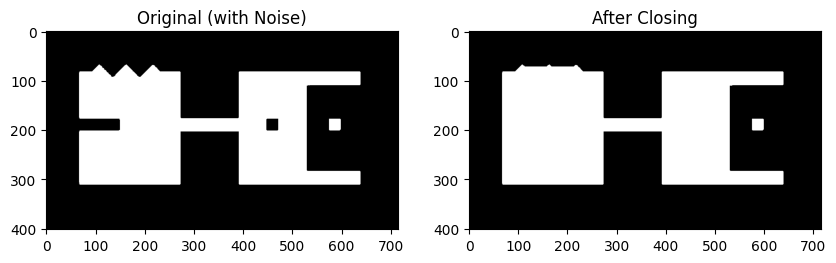

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# imgFile = 'Opening2.jpg'
imgFile = './images/Opening2.jpg'

# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 45x45 square is a good starting point)
kernel = np.ones((45, 45), np.uint8)

# 3. Apply Opening
# Effectively: cv2.erode(cv2.dilate(binary, kernel), kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original (with Noise)')
plt.subplot(1, 2, 2), plt.imshow(closing, 'gray'), plt.title('After Closing')
plt.show()

## 5. Boundary extraction

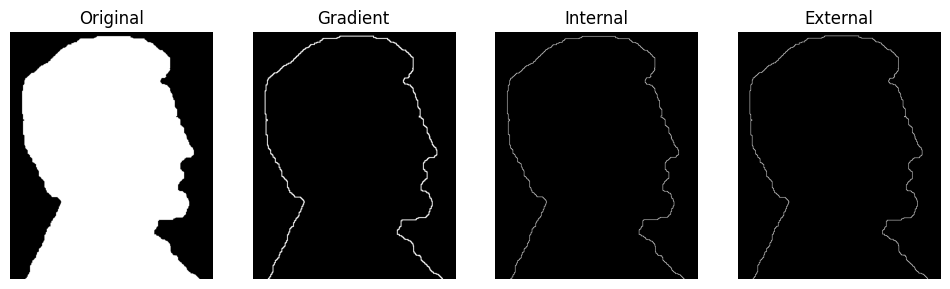

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# imgFile = 'BoundaryExtraction.jpg'
imgFile = './images/BoundaryExtraction.jpg'
# 1. Load and binarize the image (foreground must be white)
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define a kernel (the size controls boundary thickness)
kernel = np.ones((3, 3), np.uint8)

# 3. Method A: Morphological Gradient (Built-in standard)
gradient = cv2.morphologyEx(binary, cv2.MORPH_GRADIENT, kernel)

# 4. Method B: Internal Boundary (Original - Eroded)
eroded = cv2.erode(binary, kernel)
internal = cv2.subtract(binary, eroded)

# 5. Method C: External Boundary (Dilated - Original)
dilated = cv2.dilate(binary, kernel)
external = cv2.subtract(dilated, binary)

# Visualization
titles = ['Original', 'Gradient', 'Internal', 'External']
images = [binary, gradient, internal, external]

plt.figure(figsize=(12, 4))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.show()

## 6. Student tasks

### Task 1 – Apply morphological operations to a new image

Select a different binary image (e.g., Balls).

Apply the morphological operations demonstrated in the lab:

- Erosion
- Dilation
- Opening
- Closing

Display the original image and the results of each operation.

### Task 2 – Experiment with structuring elements

Apply erosion and dilation using different structuring element shapes (e.g., square, cross, and ellipse).

Experiment with different kernel sizes (3×3, 5×5, and 7×7).

Compare the resulting images.

### Task 1 Solution – Erosion, dilation, opening and closing on a new image (balls)

image: (720, 960, 3)   Otsu threshold: 168.0
Binary                 objects:  62   holes:  58   white pixels:  83304
Erosion 3x3            objects:  14   holes:   6   white pixels:  78870
Erosion 7x7            objects:   8   holes:   3   white pixels:  72429
Erosion 11x11          objects:   5   holes:   1   white pixels:  66822
Dilation 3x3           objects:  13   holes:  16   white pixels:  87797
Dilation 7x7           objects:   6   holes:   7   white pixels:  94665
Dilation 11x11         objects:   5   holes:   4   white pixels: 100900
Opening 5x5            objects:   5   holes:   5   white pixels:  81830
Closing 21x21          objects:   6   holes:   0   white pixels:  87829


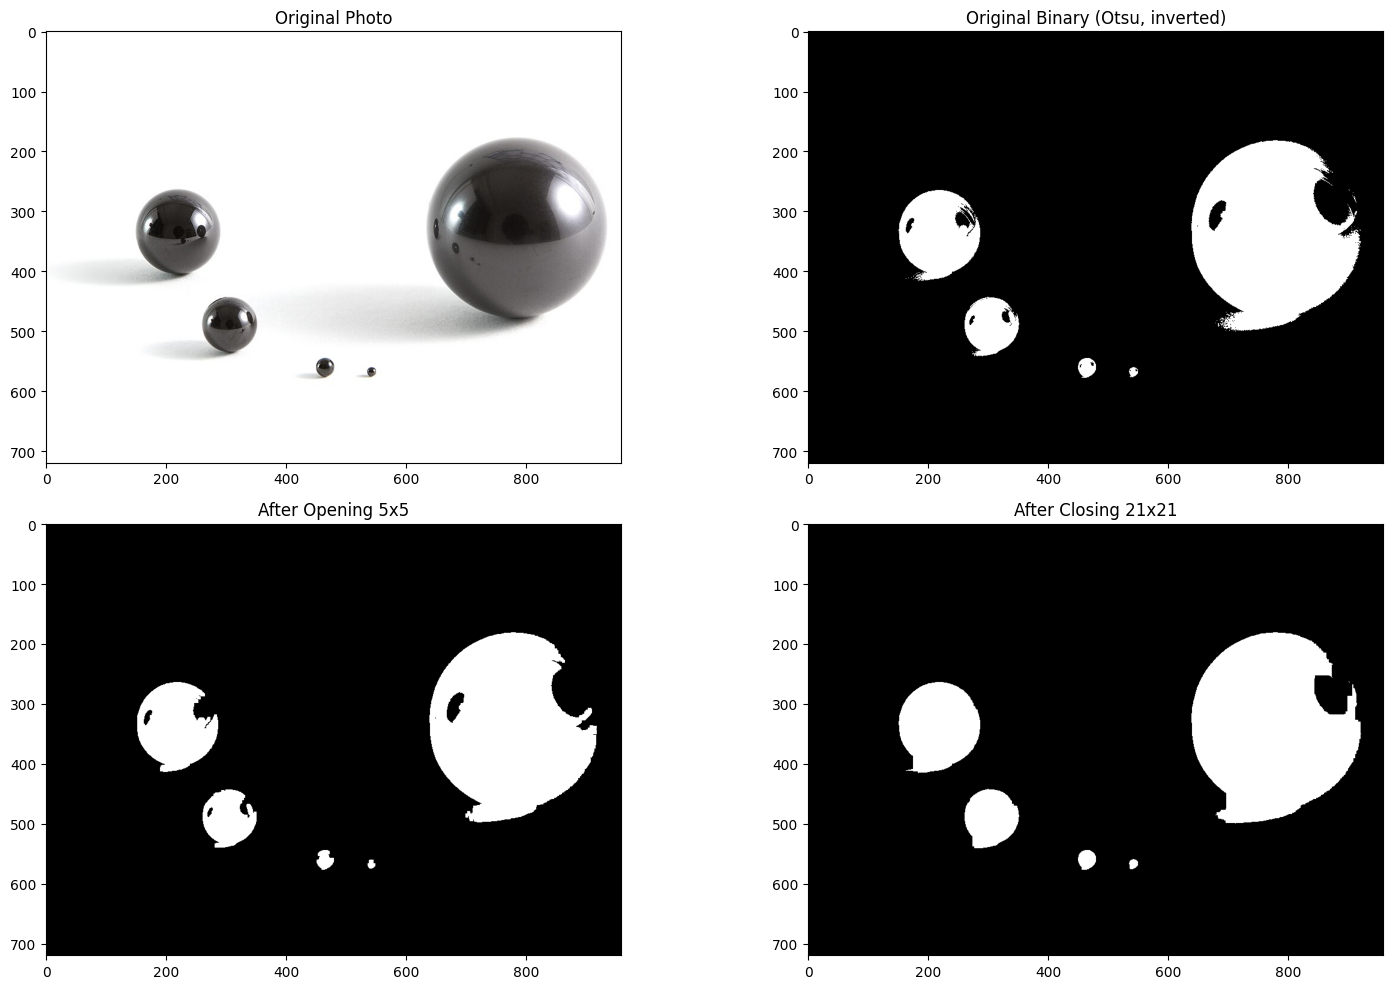

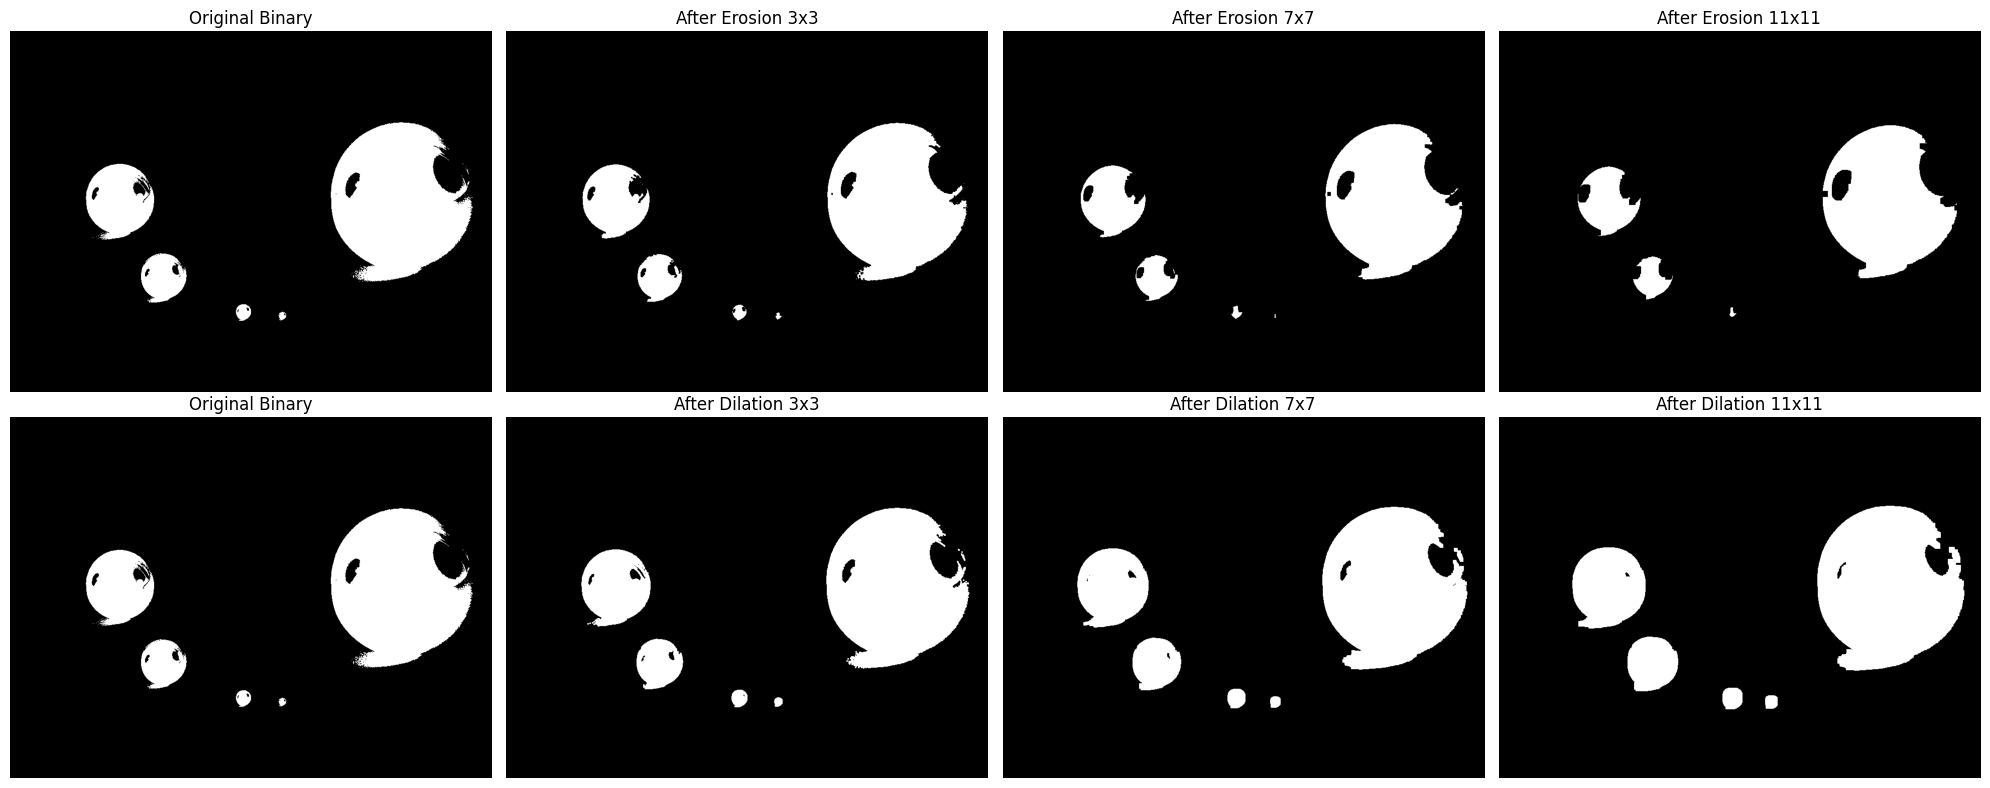

In [7]:
# new image that is not used anywhere in the labs: silicon nitride bearing balls from Wikimedia Commons
# "Silicon nitride Si3N4 bearing balls 1–20 mm.jpg" (CC BY-SA 3.0), resized to 960 px wide
taskFile = './images/balls.jpg'

# 1. Load the image and binarize it with Otsu (same as the notebook)
# the balls are dark on a white background, so THRESH_BINARY_INV makes the balls the white foreground
balls = cv2.imread(taskFile)
balls_gray = cv2.cvtColor(balls, cv2.COLOR_BGR2GRAY)
otsu_t, balls_bin = cv2.threshold(balls_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print("image:", balls.shape, "  Otsu threshold:", otsu_t)

# helpers to measure each result
def count_objects(b):          # white connected regions
    return cv2.connectedComponents(b)[0] - 1

def count_holes(b):            # black regions that do not touch the image border
    n, lab = cv2.connectedComponents(255 - b)
    border = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])))
    return len(set(range(1, n)) - border)

def describe(name, b):
    print(f"{name:<22} objects: {count_objects(b):3d}   holes: {count_holes(b):3d}   white pixels: {(b > 0).sum():6d}")

# 2. Erosion and dilation with 3x3, 7x7 and 11x11 square kernels (as in the notebook)
kernels = {k: np.ones((k, k), np.uint8) for k in (3, 7, 11)}
eroded = {k: cv2.erode(balls_bin, K, iterations=1) for k, K in kernels.items()}
dilated = {k: cv2.dilate(balls_bin, K, iterations=1) for k, K in kernels.items()}

# 3. Opening (5x5) removes the small specks, closing (21x21) fills the holes left by the reflections
balls_open = cv2.morphologyEx(balls_bin, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
balls_close = cv2.morphologyEx(balls_bin, cv2.MORPH_CLOSE, np.ones((21, 21), np.uint8))

describe("Binary", balls_bin)
for k in kernels:
    describe(f"Erosion {k}x{k}", eroded[k])
for k in kernels:
    describe(f"Dilation {k}x{k}", dilated[k])
describe("Opening 5x5", balls_open)
describe("Closing 21x21", balls_close)

# Display: original + binary + opening + closing
plt.figure(figsize=(16, 10))
plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(balls, cv2.COLOR_BGR2RGB)), plt.title('Original Photo')
plt.subplot(2, 2, 2), plt.imshow(balls_bin, 'gray'), plt.title('Original Binary (Otsu, inverted)')
plt.subplot(2, 2, 3), plt.imshow(balls_open, 'gray'), plt.title('After Opening 5x5')
plt.subplot(2, 2, 4), plt.imshow(balls_close, 'gray'), plt.title('After Closing 21x21')
plt.tight_layout()
plt.show()

# Display: erosion (top row) and dilation (bottom row)
fig, ax = plt.subplots(2, 4, figsize=(20, 8))
ax[0, 0].imshow(balls_bin, 'gray'), ax[0, 0].set_title('Original Binary')
ax[1, 0].imshow(balls_bin, 'gray'), ax[1, 0].set_title('Original Binary')
for j, k in enumerate(kernels, start=1):
    ax[0, j].imshow(eroded[k], 'gray'), ax[0, j].set_title(f'After Erosion {k}x{k}')
    ax[1, j].imshow(dilated[k], 'gray'), ax[1, j].set_title(f'After Dilation {k}x{k}')
for a in ax.ravel(): a.axis('off')
plt.tight_layout()
plt.show()

Explanation: I used a photo of silicon nitride bearing balls from Wikimedia Commons, which is not used anywhere in the labs. The balls are dark on a white background, so I binarized it with Otsu and THRESH_BINARY_INV to make the balls white. The binary image is not clean: it has 62 white objects (5 balls and 57 small specks from the shadows) and 58 black holes inside the balls from the reflections. Erosion shrinks the white, so the specks disappear and the holes grow, and with 11x11 only 5 objects are left, but the smallest ball (about 14 px wide) is almost gone. Dilation does the opposite, the balls grow and the holes shrink from 58 to 4, but the specks near the balls are joined to them. Opening 5x5 removes all the specks and keeps exactly the 5 balls with almost the same size (81,830 white pixels against 83,304), and closing 21x21 fills every hole inside the balls (0 holes left). The big reflection on the right side of the large ball is not filled, because it reaches the edge of the ball, so it is a gap in the outline and not a hole, and the square kernel leaves a square corner in it.

### Task 2 Solution – Square, cross and ellipse structuring elements (3×3, 5×5, 7×7)

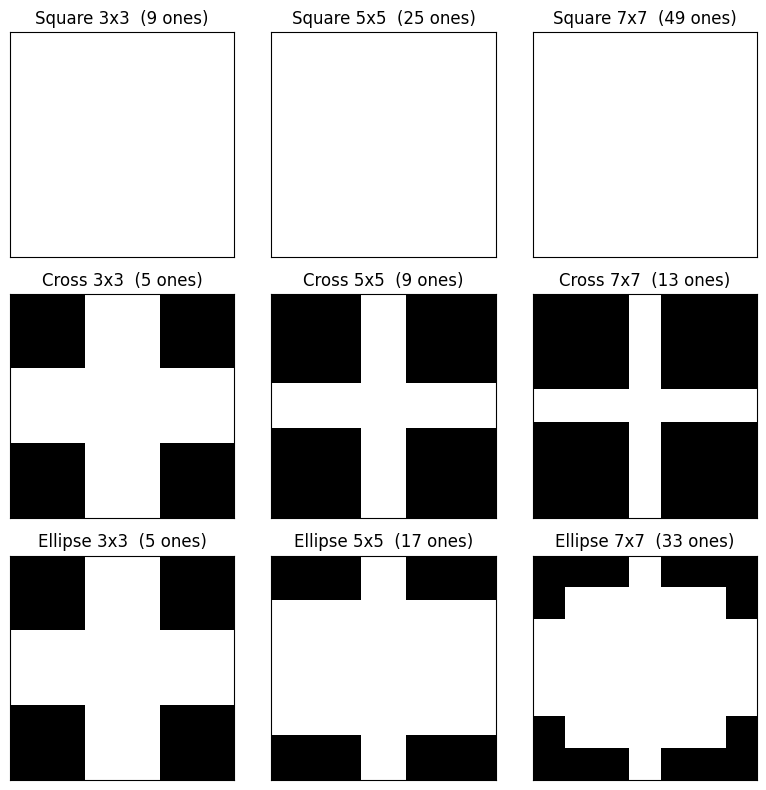

3x3 ellipse is the same as the 3x3 cross: True

SE             erosion: white px  objects  holes    dilation: white px  objects  holes
Square 3x3                 78870       14      6                 87797       13     16
Square 5x5                 75503        9      4                 91389        7     12
Square 7x7                 72429        8      3                 94665        6      7
Cross 3x3                  80085       21     11                 86529       17     15
Cross 5x5                  77788       22      4                 88956        8     27
Cross 7x7                  75678       27      4                 91220        7     27
Ellipse 3x3                80085       21     11                 86529       17     15
Ellipse 5x5                76810       11      4                 90022        7     11
Ellipse 7x7                74467        6      4                 92527        6      8


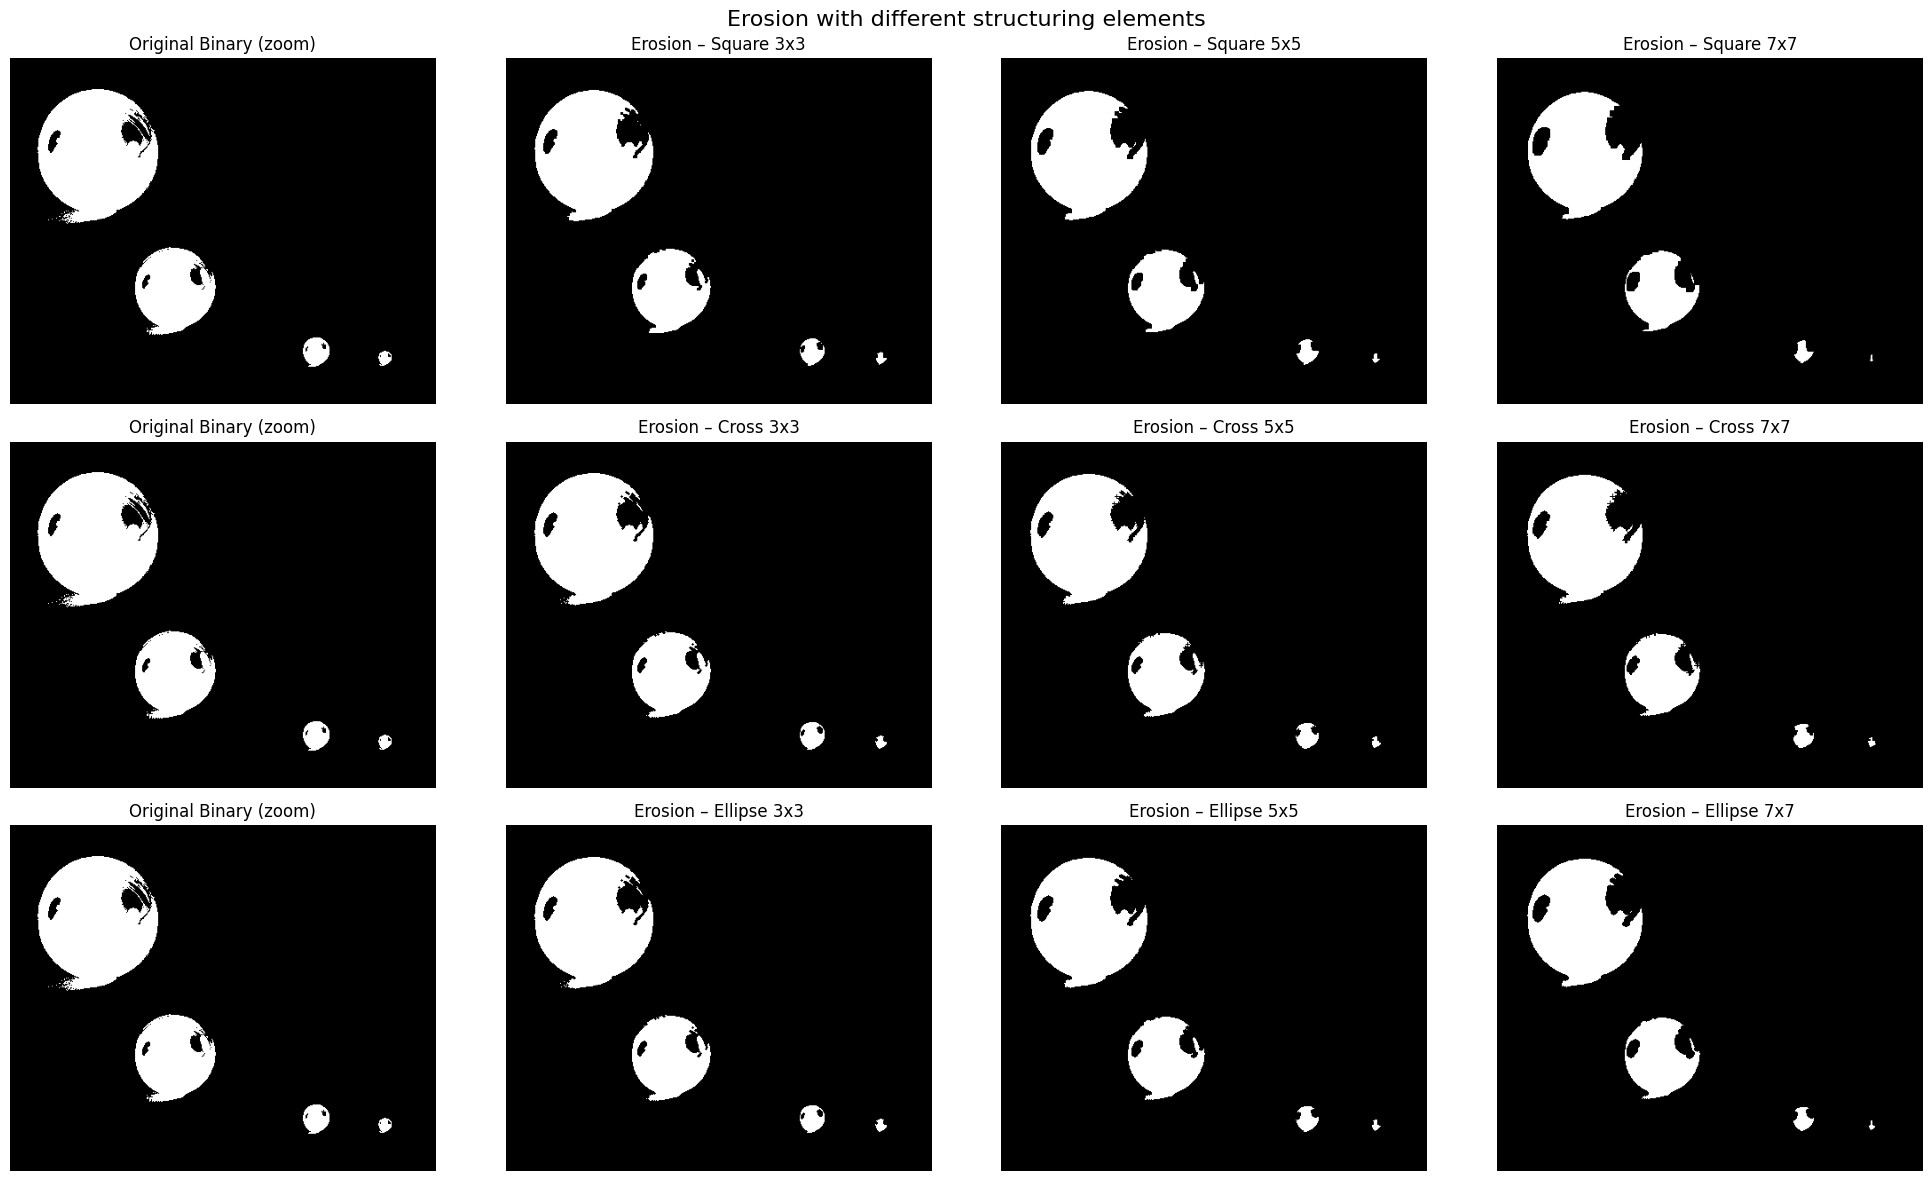

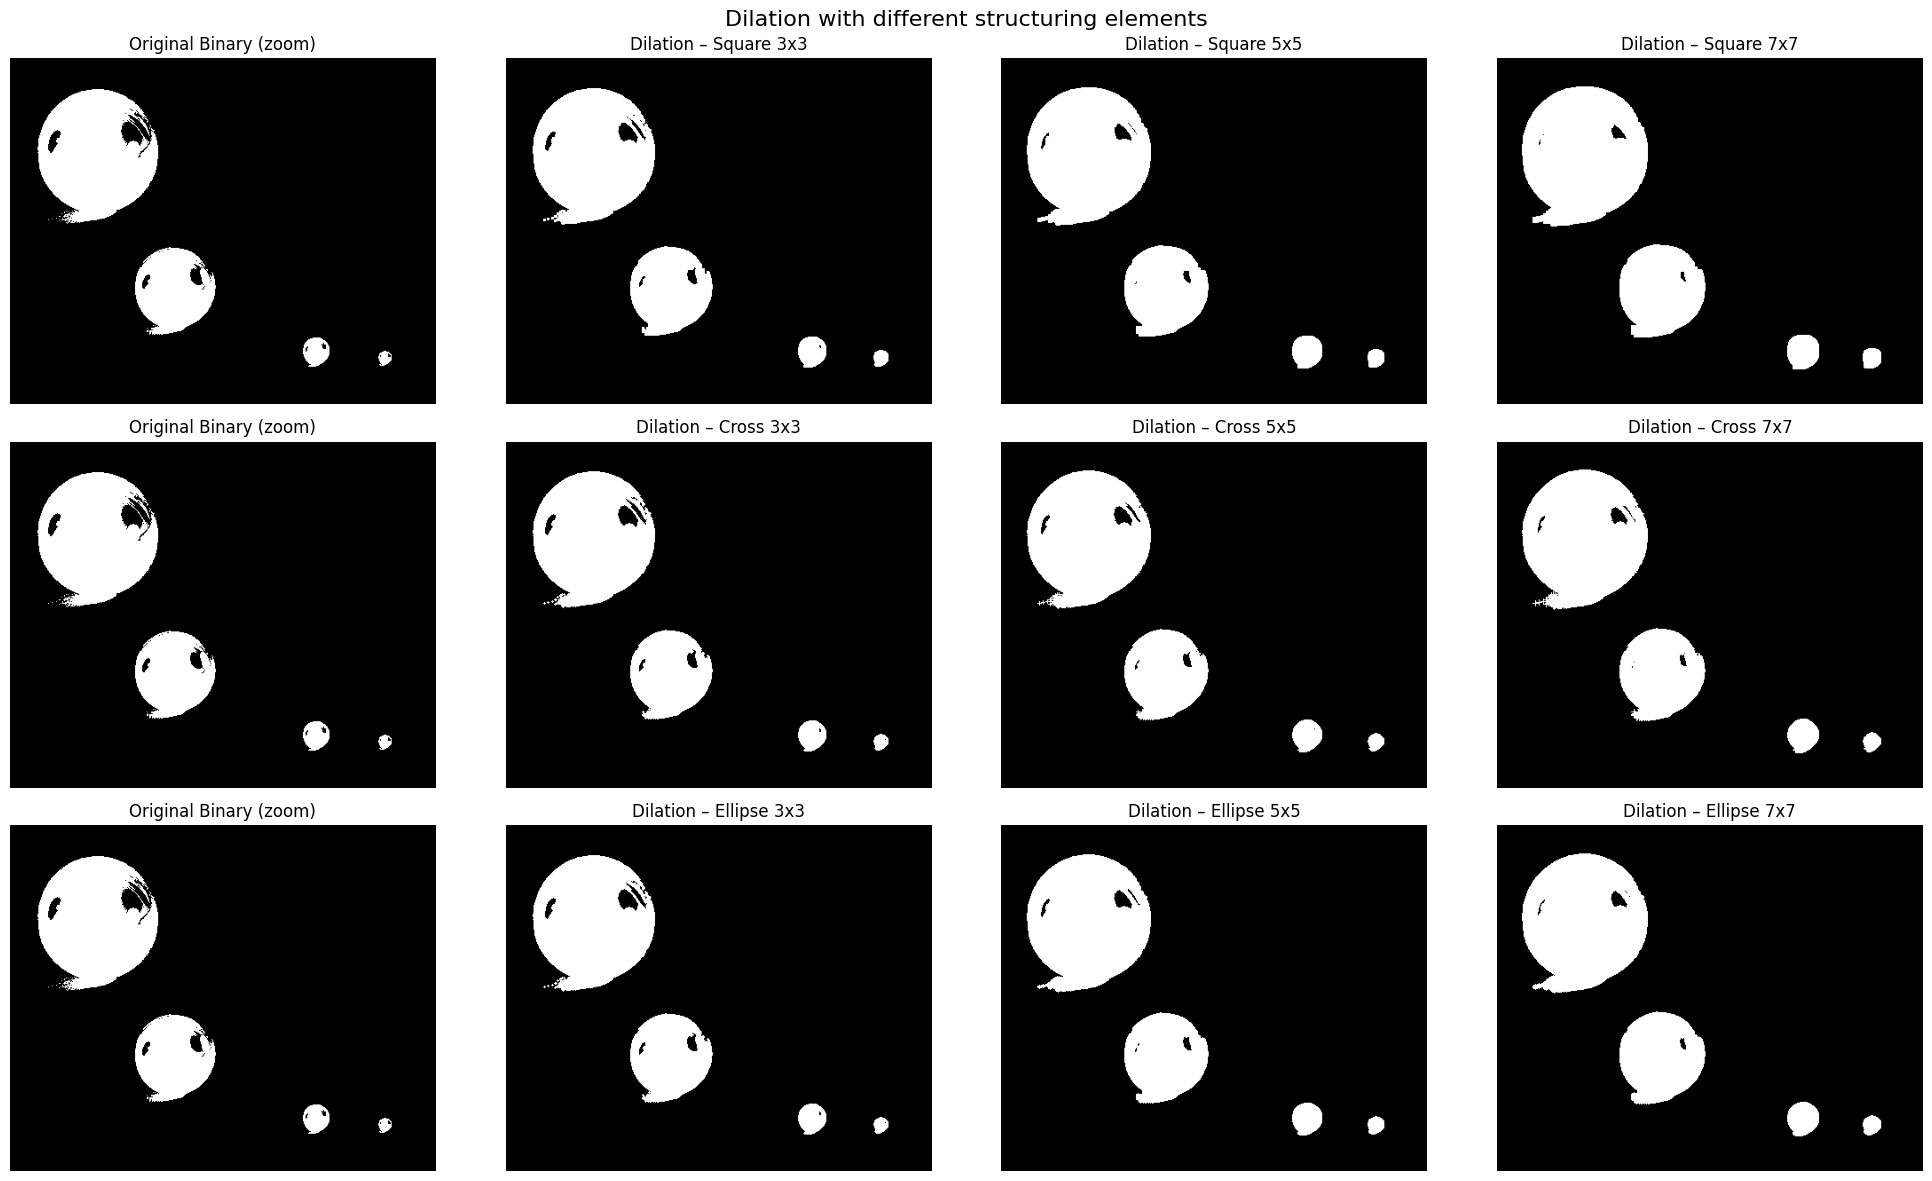

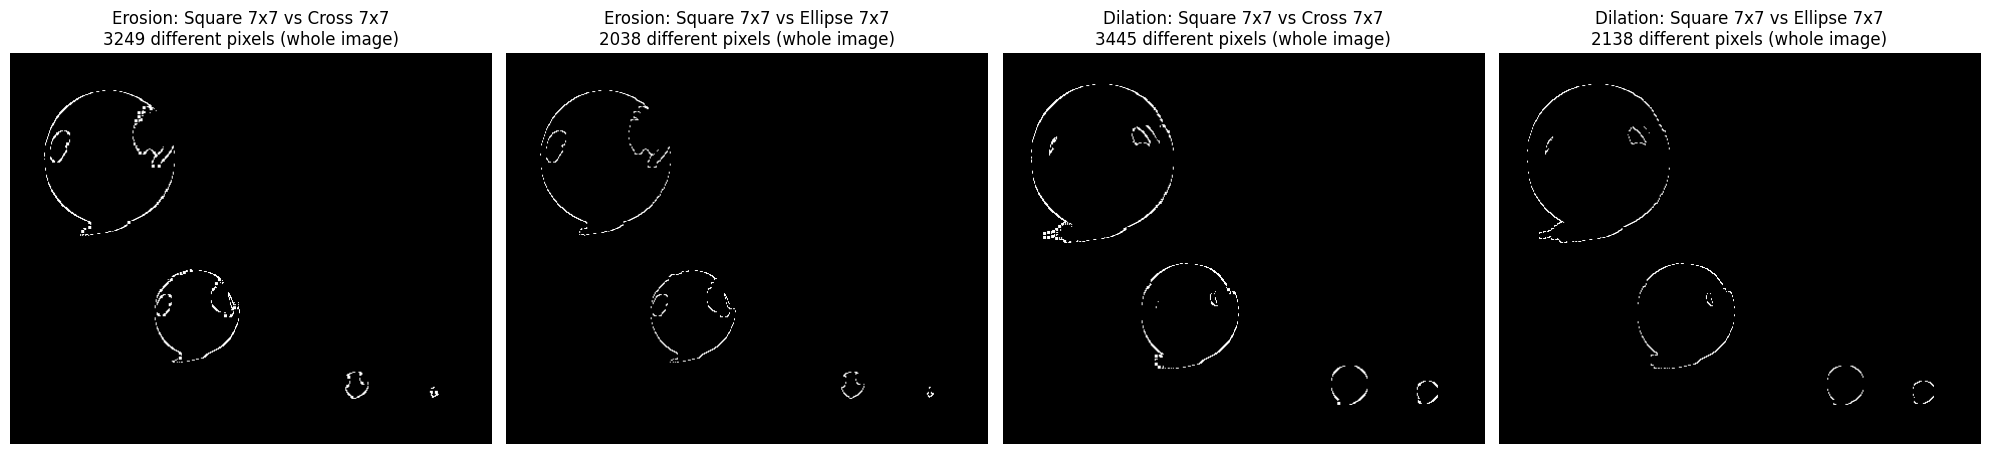

In [8]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]
ses = {(name, k): cv2.getStructuringElement(s, (k, k)) for name, s in shapes.items() for k in sizes}

# 1. The structuring elements themselves (white = 1)
fig, ax = plt.subplots(3, 3, figsize=(8, 8))
for i, name in enumerate(shapes):
    for j, k in enumerate(sizes):
        se = ses[(name, k)]
        ax[i, j].imshow(se, 'gray', vmin=0, vmax=1)
        ax[i, j].set_title(f'{name} {k}x{k}  ({se.sum()} ones)')
        ax[i, j].set_xticks([]), ax[i, j].set_yticks([])
plt.tight_layout()
plt.show()
print("3x3 ellipse is the same as the 3x3 cross:", np.array_equal(ses[('Ellipse', 3)], ses[('Cross', 3)]))

# 2. Apply erosion and dilation with every shape and size on the balls image
results = {}
print(f"\n{'SE':<14}{'erosion: white px':>18}{'objects':>9}{'holes':>7}   {'dilation: white px':>19}{'objects':>9}{'holes':>7}")
for (name, k), se in ses.items():
    e = cv2.erode(balls_bin, se)
    d = cv2.dilate(balls_bin, se)
    results[(name, k)] = (e, d)
    print(f"{name + f' {k}x{k}':<14}{(e > 0).sum():>18}{count_objects(e):>9}{count_holes(e):>7}   "
          f"{(d > 0).sum():>19}{count_objects(d):>9}{count_holes(d):>7}")

# 3. Compare the results on a zoom of the smaller balls (rows = shape, columns = size)
crop = (slice(230, 620), slice(120, 600))
for op, idx in (('Erosion', 0), ('Dilation', 1)):
    fig, ax = plt.subplots(3, 4, figsize=(20, 12))
    for i, name in enumerate(shapes):
        ax[i, 0].imshow(balls_bin[crop], 'gray'), ax[i, 0].set_title('Original Binary (zoom)')
        for j, k in enumerate(sizes, start=1):
            ax[i, j].imshow(results[(name, k)][idx][crop], 'gray')
            ax[i, j].set_title(f'{op} – {name} {k}x{k}')
    for a in ax.ravel(): a.axis('off')
    plt.suptitle(f'{op} with different structuring elements', fontsize=16)
    plt.tight_layout()
    plt.show()

# 4. Where the shapes differ: pixels that the 7x7 square changes but the 7x7 cross / ellipse do not
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
pairs = [('Erosion', 0, 'Cross'), ('Erosion', 0, 'Ellipse'), ('Dilation', 1, 'Cross'), ('Dilation', 1, 'Ellipse')]
for a, (op, idx, name) in zip(ax, pairs):
    diff = cv2.absdiff(results[('Square', 7)][idx], results[(name, 7)][idx])
    a.imshow(diff[crop], 'gray'), a.set_title(f'{op}: Square 7x7 vs {name} 7x7\n{(diff > 0).sum()} different pixels (whole image)')
    a.axis('off')
plt.tight_layout()
plt.show()

Explanation: The square has all 49 ones at 7x7, the cross only 13 and the ellipse 33, so for the same size the square has the strongest effect and the cross the weakest: erosion 7x7 keeps 72,429 white pixels with the square, 74,467 with the ellipse and 75,678 with the cross, and dilation 7x7 gives 94,665, 92,527 and 91,220. A bigger kernel always gives a stronger effect for every shape. The shape also changes the result: the square makes the outlines blocky, the ellipse keeps the balls round, and the cross misses the diagonal directions, so the shadow specks are split into pieces instead of removed (27 objects after cross erosion 7x7 against 8 with the square) and many small holes stay after cross dilation (27 holes). The difference images show that the shapes only differ on the edges of the balls and the holes, 2,000 to 3,500 pixels out of 691,200. In OpenCV the 3x3 ellipse is exactly the same as the 3x3 cross, so those two rows give the same numbers. For round objects like the balls the ellipse is the best choice.

## 7. Extra experiments

### Experiment 1 – Erosion2.jpg (the image that the notebook ships but never uses)

Letters as foreground  objects:  27   holes:   8   white pixels: 338832
Erosion 15x15 (INV)    objects:  26   holes:   8   white pixels: 189289
Dilation 15x15 (INV)   objects:  21   holes:   7   white pixels: 489947
Closing 15x15 (INV)    objects:  21   holes:   6   white pixels: 345628


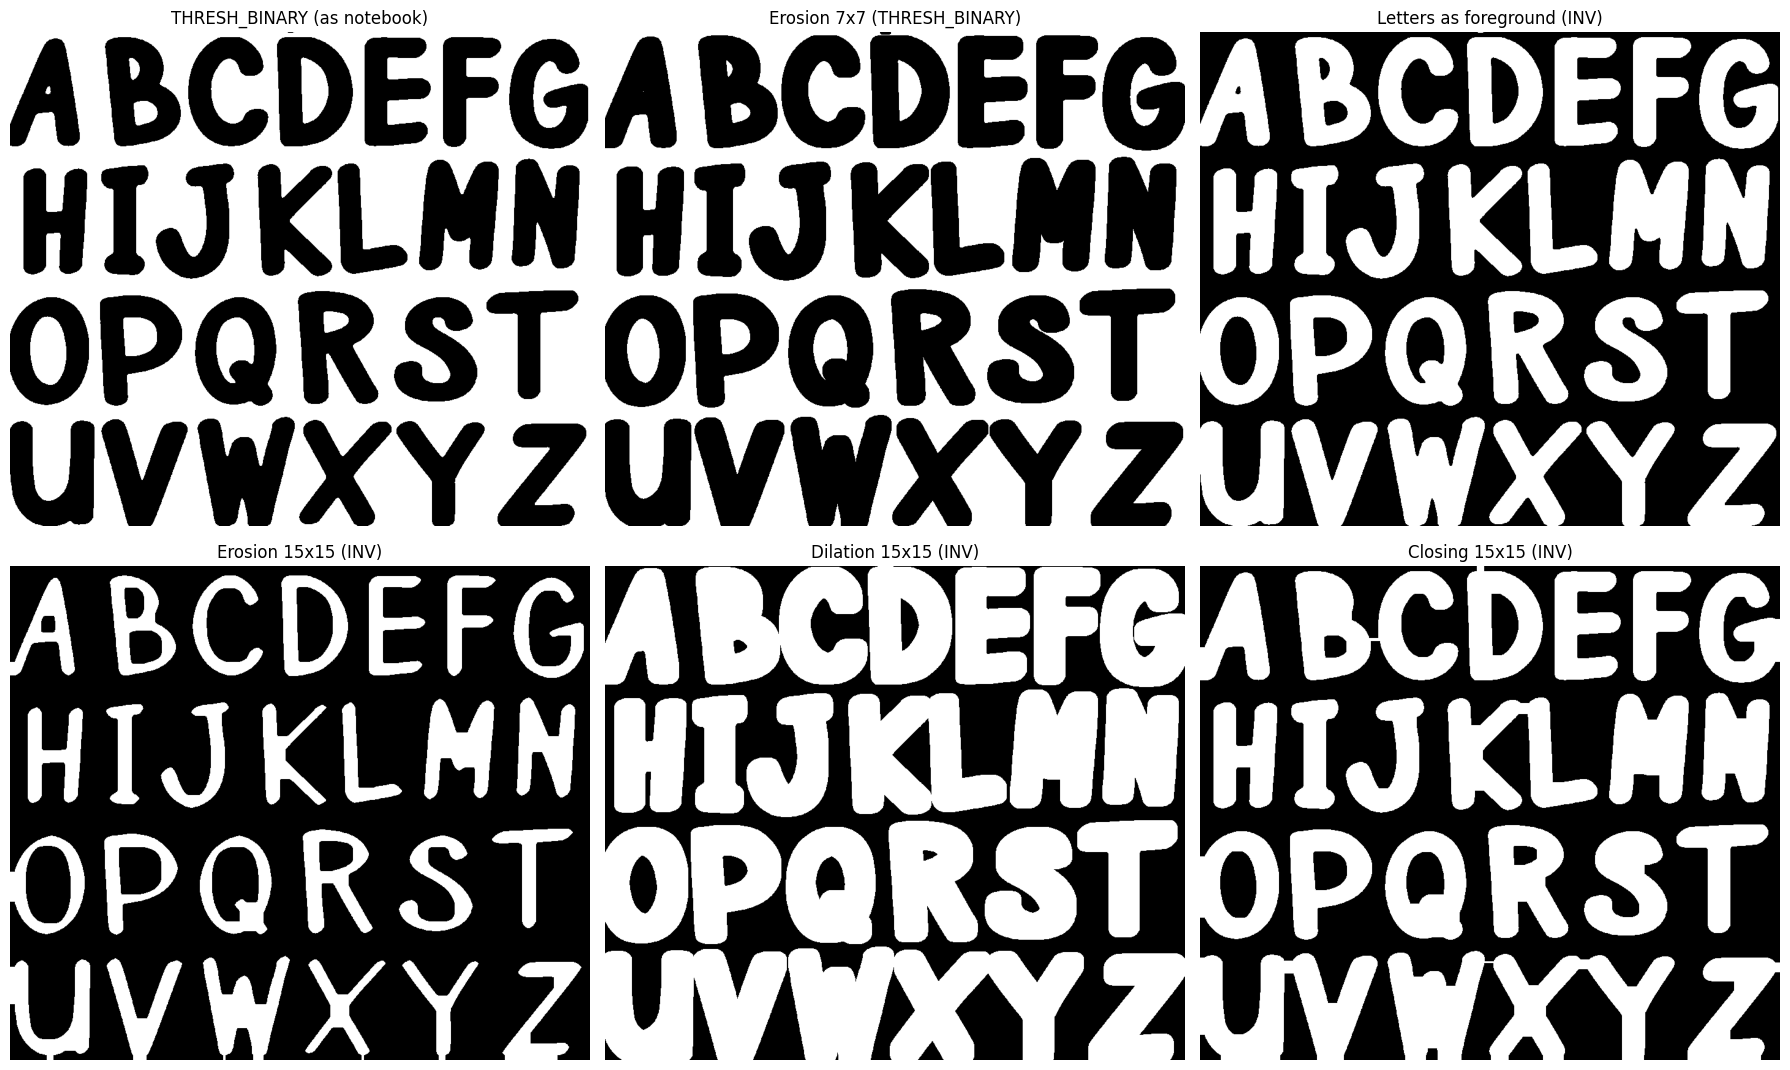

In [9]:
letters = cv2.imread('./images/Erosion2.jpg', 0)

# the letters are black on white, so the notebook's THRESH_BINARY makes the background the foreground
_, bg_fg = cv2.threshold(letters, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, letters_fg = cv2.threshold(letters, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

k7 = np.ones((7, 7), np.uint8)
k15 = np.ones((15, 15), np.uint8)
tests = {
    'THRESH_BINARY (as notebook)': bg_fg,
    'Erosion 7x7 (THRESH_BINARY)': cv2.erode(bg_fg, k7),
    'Letters as foreground (INV)': letters_fg,
    'Erosion 15x15 (INV)': cv2.erode(letters_fg, k15),
    'Dilation 15x15 (INV)': cv2.dilate(letters_fg, k15),
    'Closing 15x15 (INV)': cv2.morphologyEx(letters_fg, cv2.MORPH_CLOSE, k15),
}
for name, b in tests.items():
    if '(INV)' in name:
        describe(name[:22], b)

fig, ax = plt.subplots(2, 3, figsize=(18, 11))
for a, (name, b) in zip(ax.ravel(), tests.items()):
    a.imshow(b, 'gray'), a.set_title(name), a.axis('off')
plt.tight_layout()
plt.show()

Explanation: The notebook ships Erosion2.jpg but never uses it. The letters are black on a white background, so with the THRESH_BINARY of the notebook the background becomes the foreground, and an erosion makes the letters thicker, which looks like a dilation. With THRESH_BINARY_INV the letters are the foreground and the operations do what their names say: erosion 15x15 makes the letters thin (338,832 to 189,289 white pixels) without breaking them because the font is thick, dilation 15x15 joins the letters together (27 objects to 21) and shrinks the holes in A, B, D, O, P, Q and R, and closing joins letters that are close (B with C, W with X) but keeps the thickness of the letters. So the polarity of the binary image decides what each operation does.

### Experiment 2 – Repeated iterations vs one bigger kernel

erode: 3x3 with iterations=3  ==  7x7 once ? True
erode: 3x3 with iterations=5  ==  11x11 once ? True
dilate: 3x3 with iterations=3  ==  7x7 once ? True
dilate: 3x3 with iterations=5  ==  11x11 once ? True

3x3 x 5 iterations: 0.174 ms    11x11 once: 0.238 ms


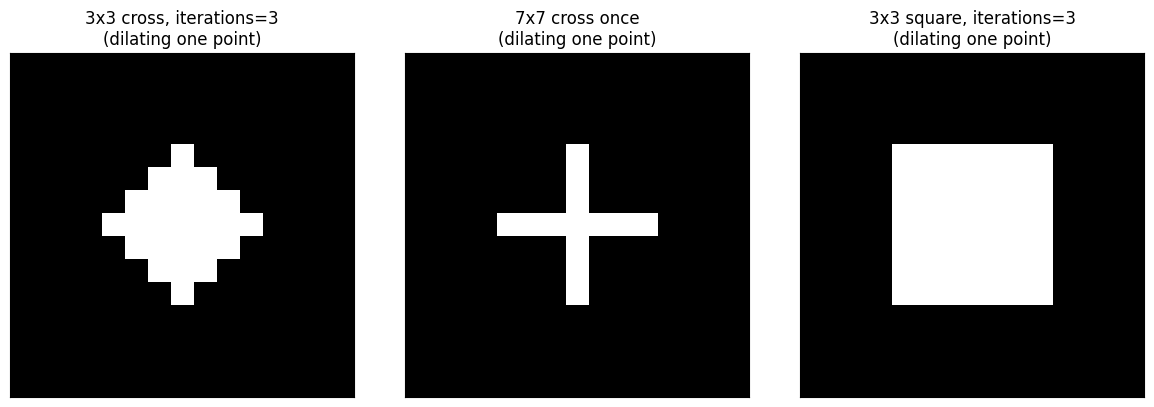

In [10]:
# erosion with a 3x3 square repeated n times should equal one erosion with a (2n+1)x(2n+1) square
binary_chip = cv2.threshold(cv2.imread('./images/Erosion.jpg', 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
for op_name, op in (('erode', cv2.erode), ('dilate', cv2.dilate)):
    for n in (3, 5):
        big = 2 * n + 1
        a = op(binary_chip, np.ones((3, 3), np.uint8), iterations=n)
        b = op(binary_chip, np.ones((big, big), np.uint8), iterations=1)
        print(f"{op_name}: 3x3 with iterations={n}  ==  {big}x{big} once ? {np.array_equal(a, b)}")

# timing on the balls image
import timeit
t_iter = timeit.timeit(lambda: cv2.erode(balls_bin, np.ones((3, 3), np.uint8), iterations=5), number=200) / 200 * 1000
t_big = timeit.timeit(lambda: cv2.erode(balls_bin, np.ones((11, 11), np.uint8)), number=200) / 200 * 1000
print(f"\n3x3 x 5 iterations: {t_iter:.3f} ms    11x11 once: {t_big:.3f} ms")

# it does not hold for the cross: repeating a 3x3 cross gives a diamond, not a 7x7 cross
cross3 = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
point = np.zeros((15, 15), np.uint8); point[7, 7] = 255
grown = {'3x3 cross, iterations=3': cv2.dilate(point, cross3, iterations=3),
         '7x7 cross once': cv2.dilate(point, cv2.getStructuringElement(cv2.MORPH_CROSS, (7, 7))),
         '3x3 square, iterations=3': cv2.dilate(point, np.ones((3, 3), np.uint8), iterations=3)}
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (name, g) in zip(ax, grown.items()):
    a.imshow(g, 'gray'), a.set_title(f'{name}\n(dilating one point)'), a.set_xticks([]), a.set_yticks([])
plt.tight_layout()
plt.show()

Explanation: Erosion or dilation with a 3x3 square repeated n times gives exactly the same result as one erosion or dilation with a (2n+1)x(2n+1) square, so iterations=3 is the same as 7x7 and iterations=5 is the same as 11x11. Both took a fraction of a millisecond on the balls image. This only works for the square: dilating a single point 3 times with the 3x3 cross gives a diamond, not the 7x7 cross, because each iteration grows the shape in all four directions.

### Experiment 3 – Checking the properties of opening and closing

In [11]:
K5 = np.ones((5, 5), np.uint8)
A = balls_bin
opened = cv2.morphologyEx(A, cv2.MORPH_OPEN, K5)
closed = cv2.morphologyEx(A, cv2.MORPH_CLOSE, K5)

# the notebook comments: opening = dilate(erode(A)), closing = erode(dilate(A))
print("opening == dilate(erode(A))      :", np.array_equal(opened, cv2.dilate(cv2.erode(A, K5), K5)))
print("closing == erode(dilate(A))      :", np.array_equal(closed, cv2.erode(cv2.dilate(A, K5), K5)))

# opening only removes pixels and closing only adds pixels
print("opening is inside A              :", not np.any(opened > A))
print("A is inside closing              :", not np.any(A > closed))

# idempotence: applying them a second time changes nothing
print("open(open(A)) == open(A)         :", np.array_equal(cv2.morphologyEx(opened, cv2.MORPH_OPEN, K5), opened))
print("close(close(A)) == close(A)      :", np.array_equal(cv2.morphologyEx(closed, cv2.MORPH_CLOSE, K5), closed))

# duality: eroding the white is the same as dilating the black
dual = 255 - cv2.dilate(255 - A, K5)
print("erode(A) == NOT dilate(NOT A)    :", np.array_equal(cv2.erode(A, K5), dual))

# the iterations argument of morphologyEx repeats each step, it does not repeat the whole opening
o2 = cv2.morphologyEx(A, cv2.MORPH_OPEN, K5, iterations=2)
print("open with iterations=2 == dilate(dilate(erode(erode(A)))):",
      np.array_equal(o2, cv2.dilate(cv2.erode(A, K5, iterations=2), K5, iterations=2)))

opening == dilate(erode(A))      : True
closing == erode(dilate(A))      : True
opening is inside A              : True
A is inside closing              : True
open(open(A)) == open(A)         : True
close(close(A)) == close(A)      : True
erode(A) == NOT dilate(NOT A)    : True
open with iterations=2 == dilate(dilate(erode(erode(A)))): True


Explanation: All the properties held on the balls image. Opening is exactly erosion then dilation and closing is dilation then erosion, as the notebook comments say. Opening only removes white pixels and closing only adds them, and applying them a second time changes nothing (they are idempotent), which is why opening and closing are good for cleaning an image. Eroding the white is the same as dilating the black (duality), which explains Experiment 1. Also, iterations=2 in morphologyEx repeats each step (erode, erode, dilate, dilate) and does not repeat the whole opening twice.

### Experiment 4 – Counting and measuring the balls

objects before cleaning: 62   after opening + closing: 5

ball 1: area  62473 px   box 280 x 318   equivalent diameter  282.0 px
ball 2: area  14515 px   box 136 x 151   equivalent diameter  135.9 px
ball 3: area   6561 px   box  91 x  98   equivalent diameter   91.4 px
ball 4: area    729 px   box  30 x  33   equivalent diameter   30.5 px
ball 5: area    162 px   box  14 x  17   equivalent diameter   14.4 px


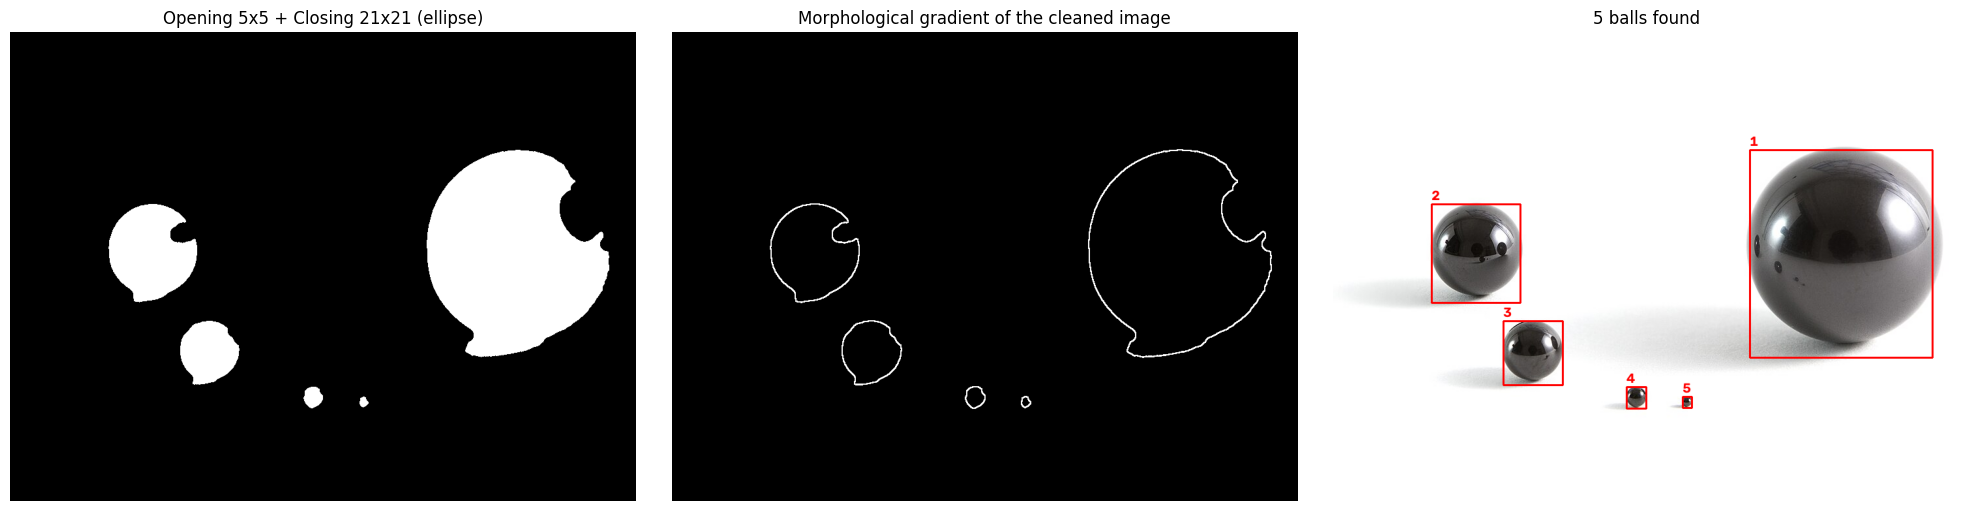

In [12]:
# clean the binary image: opening removes the specks, closing fills the reflections
clean = cv2.morphologyEx(balls_bin, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
clean = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21)))

n_raw = count_objects(balls_bin)
n, lab, stats, cent = cv2.connectedComponentsWithStats(clean)
print(f"objects before cleaning: {n_raw}   after opening + closing: {n - 1}\n")

out = cv2.cvtColor(balls, cv2.COLOR_BGR2RGB).copy()
order = np.argsort(-stats[1:, cv2.CC_STAT_AREA]) + 1
for rank, i in enumerate(order, start=1):
    x, y, w, h, area = stats[i]
    d_area = 2 * np.sqrt(area / np.pi)            # diameter of a circle with the same area
    print(f"ball {rank}: area {area:6d} px   box {w:3d} x {h:3d}   equivalent diameter {d_area:6.1f} px")
    cv2.rectangle(out, (x, y), (x + w, y + h), (255, 0, 0), 2)
    cv2.putText(out, str(rank), (x, max(y - 6, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)

# outlines of the cleaned balls with the morphological gradient (section 5)
outline = cv2.morphologyEx(clean, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8))

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
ax[0].imshow(clean, 'gray'), ax[0].set_title('Opening 5x5 + Closing 21x21 (ellipse)')
ax[1].imshow(outline, 'gray'), ax[1].set_title('Morphological gradient of the cleaned image')
ax[2].imshow(out), ax[2].set_title(f'{n - 1} balls found')
for a in ax: a.axis('off')
plt.tight_layout()
plt.show()

Explanation: As an application, I cleaned the balls image with an elliptical opening 5x5 and closing 21x21 and counted the objects with connected components: 62 objects before the cleaning and exactly 5 after it, one for each ball. The equivalent diameters are 282, 136, 91, 30.5 and 14.4 px, so if the biggest ball is 20 mm (the file name says 1–20 mm) the smallest one comes out about 1 mm, which matches. The morphological gradient from section 5 gives the outline of each ball. The box of the big ball is taller than wide, because a part of its shadow is dark enough to be included in the binary image.